In [1]:
import time
import ROOT
import math
import numpy as np
import pandas as pd
import uproot
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LogNorm
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
import matplotlib.gridspec as gridspec

Welcome to JupyROOT 6.24/06


In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

In [3]:
def addNewBranches(inputDataframe):
    df_temp = inputDataframe
    df_temp.eval('dm=m-mg',inplace=True)
    df_temp.eval('dm_frac=dm/m',inplace=True)
    df_temp.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
    df_temp[df_temp.a<0.000001]['a'] = 0
    df_temp[['loga']] = np.log10(df_temp[['a']].replace(0, np.nan))
    df_temp.mask(df_temp.isna(),-4.1,inplace=True)
    return df_temp

In [4]:
def weighted_avg_and_std(values, weights):
    """
    Return the weighted average and standard deviation.

    values, weights -- NumPy ndarrays with the same shape.
    """
    average = np.average(values, weights=weights)
    # Fast and numerically precise:
    variance = np.average((values-average)**2, weights=weights)
    return (average, math.sqrt(variance))

In [5]:
observables2 = ['pt','m','q2','rg','zg','mg','w','reject']
observabless2 = ['pts','ms','q2s','rgs','zgs','mgs','ws','rejects']
inputFiles = ['/vast/palmer/home.grace/ys668/output/run12/all0818_2.root']
treeName = ["MatchedTree"]

In [6]:
rgedges=np.arange(0.,0.45,0.05)
zgedges=np.arange(0.1,0.55,0.05)

In [7]:
path = '/gpfs/gibbs/project/caines/ys668/run12/csvs/'
ofCsvPath = 'newemb_6d_largebatch_092723/'
ofCuts = '20<pt<30 and rg!=-1'
it = 15

df2s = []
for i in range(1,21):
    df_temp = pd.read_csv(path+ofCsvPath+'jet_noweight.csv', low_memory=False)
    df_temp.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
    df_temp.eval('loga=log10(a)',inplace=True)
    df_temp['weight'] = pd.read_csv(path+ofCsvPath+'it'+str(it)+'_seed'+str(i)+'.csv', low_memory=False)
    df2s.append(applyCut(df_temp, ofCuts))

In [8]:
w = []
for i in range(0, len(df2s)):
    w.append(np.asarray(df2s[i]['weight']))
w_avg=np.average(w,axis=0)
w_std=np.std(w,axis=0)
df2 = df2s[0]
df2['w_avg'] = w_avg
df2 = addNewBranches(df2)

/tmp/ipykernel_867534/1898836142.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)


In [9]:
z2 = np.zeros((len(rgedges)-1, len(zgedges)-1))
z2_err = np.zeros((len(rgedges)-1, len(zgedges)-1))
for i in range(0, len(rgedges)-1):
    for j in range(0, len(zgedges)-1):
        df_temp = df2[(df2.rg>rgedges[i]) & (df2.rg<=rgedges[i+1]) & (df2.zg>zgedges[j]) & (df2.zg<=zgedges[j+1])]
        avg, err = weighted_avg_and_std(df_temp['a'], weights=df_temp['w_avg'])
        z2[i][j] = avg
        z2_err[i][j] = err

In [10]:
def func(x, te):
    return 1/2 * (1-np.sqrt(1- 2/(te * (1-np.cos(x)))))

In [11]:
x0 = np.arange(0.,0.401,0.001)
y0 = func(x0,50)
x1 = np.arange(0.,0.401,0.001)
y1 = func(x1,200)
x2 = np.arange(0.,0.401,0.001)
y2 = func(x2,800)

/tmp/ipykernel_867534/1000708699.py:2: RuntimeWarning: divide by zero encountered in divide
  return 1/2 * (1-np.sqrt(1- 2/(te * (1-np.cos(x)))))
/tmp/ipykernel_867534/1000708699.py:2: RuntimeWarning: invalid value encountered in sqrt
  return 1/2 * (1-np.sqrt(1- 2/(te * (1-np.cos(x)))))


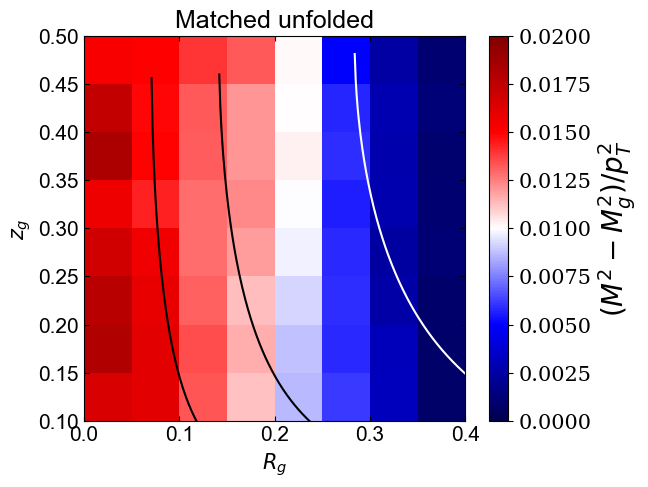

In [12]:
plt.rcParams['font.family'] = 'arial'
plt.rcParams['font.size'] = '15'

gs1 = gridspec.GridSpec(1,2,width_ratios=(1,12))

fig = plt.figure(figsize=(7,5))
plt.subplots_adjust(wspace=0.1, hspace=0)

ax1 = fig.add_subplot(gs1[1])
plt.pcolormesh(rgedges, zgedges, np.transpose(z2), cmap='seismic')
#plt.errorbar(np.arange(0.025,0.425,0.05), y_1d, yerr=0, color='k')
#plt.text(0.05,0.2,'$p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ full jets, R=0.4, |$\eta$|<0.6\n\nMultiFolded with $p_\mathrm{T}, Q, M, M_g, R_g, z_g$\n\n$20 < p_\mathrm{T} < 30$ GeV/$c$', color='k',fontsize=10)
ax1.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both', labelcolor='k')
#ax1.axes.yaxis.set_ticklabels([])
#ax1.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
plt.ylabel(r'$z_g$')
plt.xlabel(r'$R_g$')
#plt.xticks(np.arange(0,1.1,0.1))
plt.clim(0,0.02)
plt.ylim(0.1,0.5)
plt.plot(x0,y0, color='white')
plt.plot(x1,y1, color='k')
plt.plot(x2,y2, color='k')
plt.title('Matched unfolded')
cbar = plt.colorbar()
for l in cbar.ax.yaxis.get_ticklabels():
    l.set_family("serif")
cbar.set_label(r'$(M^2-M_g^2)/p_T^2$',font='arial',fontsize=20)

In [13]:
def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

In [14]:
df1 = addNewBranches(applyCut(getData(observables2+observabless2, inputFiles[0], treeName[0]), ofCuts+' and reject<=0 and rejects<=0 and (pts<15 or ms<1)'))

/tmp/ipykernel_867534/1898836142.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_temp[df_temp.a<0.000001]['a'] = 0
/gpfs/gibbs/project/caines/ys668/conda_envs/my_env_2/lib/python3.10/site-packages/pandas/core/internals/blocks.py:329: RuntimeWarning: invalid value encountered in log10
  result = func(self.values, **kwargs)


In [15]:
z1 = np.zeros((len(rgedges)-1, len(zgedges)-1))
z1_err = np.zeros((len(rgedges)-1, len(zgedges)-1))
for i in range(0, len(rgedges)-1):
    for j in range(0, len(zgedges)-1):
        df_temp = df1[(df1.rg>rgedges[i]) & (df1.rg<=rgedges[i+1]) & (df1.zg>zgedges[j]) & (df1.zg<=zgedges[j+1])]
        avg, err = weighted_avg_and_std(df_temp['a'], weights=df_temp['w'])
        z1[i][j] = avg
        z1_err[i][j] = err

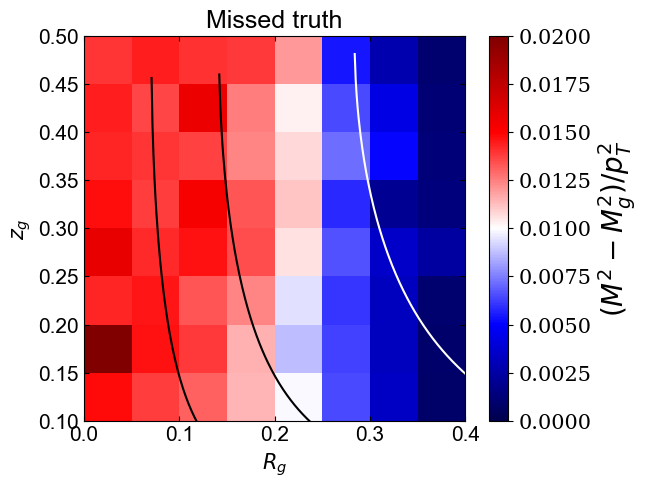

In [16]:
gs1 = gridspec.GridSpec(1,2,width_ratios=(1,12))

fig = plt.figure(figsize=(7,5))
plt.subplots_adjust(wspace=0.1, hspace=0)

ax1 = fig.add_subplot(gs1[1])
plt.pcolormesh(rgedges, zgedges, np.transpose(z1), cmap='seismic')
#plt.errorbar(np.arange(0.025,0.425,0.05), y_1d, yerr=0, color='k')
#plt.text(0.05,0.2,'$p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ full jets, R=0.4, |$\eta$|<0.6\n\nMultiFolded with $p_\mathrm{T}, Q, M, M_g, R_g, z_g$\n\n$20 < p_\mathrm{T} < 30$ GeV/$c$', color='k',fontsize=10)
ax1.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both', labelcolor='k')
#ax1.axes.yaxis.set_ticklabels([])
#ax1.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
plt.ylabel(r'$z_g$')
plt.xlabel(r'$R_g$')
#plt.xticks(np.arange(0,1.1,0.1))
plt.clim(0,0.02)
plt.ylim(0.1,0.5)
plt.plot(x0,y0, color='white')
plt.plot(x1,y1, color='k')
plt.plot(x2,y2, color='k')
plt.title('Missed truth')
cbar = plt.colorbar()
for l in cbar.ax.yaxis.get_ticklabels():
    l.set_family("serif")
cbar.set_label(r'$(M^2-M_g^2)/p_T^2$',font='arial',fontsize=20)

In [17]:
df_truth = applyCut(getData(observables2+observabless2, inputFiles[0], treeName[0]), ofCuts+' and reject<=0 and rejects<=0')
match_miss = np.histogram2d(df_truth['rg'],df_truth['zg'], bins=[rgedges,zgedges], weights=df_truth['w'])[0]
match = np.histogram2d(df_truth[(df_truth.ms>1) & (df_truth.pts>15)]['rg'], df_truth[(df_truth.ms>1) & (df_truth.pts>15)]['zg'], bins=[rgedges,zgedges], weights=df_truth[(df_truth.ms>1) & (df_truth.pts>15)]['w'])[0]
eff = match/match_miss

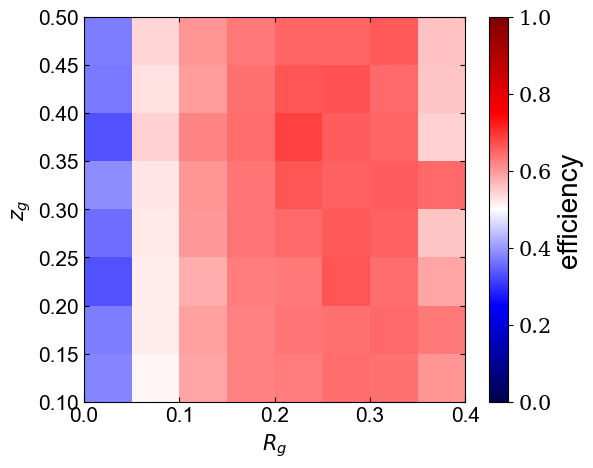

In [18]:
gs1 = gridspec.GridSpec(1,2,width_ratios=(1,12))

fig = plt.figure(figsize=(7,5))
plt.subplots_adjust(wspace=0.1, hspace=0)

ax1 = fig.add_subplot(gs1[1])
plt.pcolormesh(rgedges, zgedges, np.transpose(eff), cmap='seismic')
ax1.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both', labelcolor='k')
#ax1.axes.yaxis.set_ticklabels([])
#ax1.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
plt.ylabel(r'$z_g$')
plt.xlabel(r'$R_g$')
#plt.xticks(np.arange(0,1.1,0.1))
plt.clim(0,1)
plt.ylim(0.1,0.5)
cbar = plt.colorbar()
for l in cbar.ax.yaxis.get_ticklabels():
    l.set_family("serif")
cbar.set_label('efficiency',font='arial',fontsize=20)

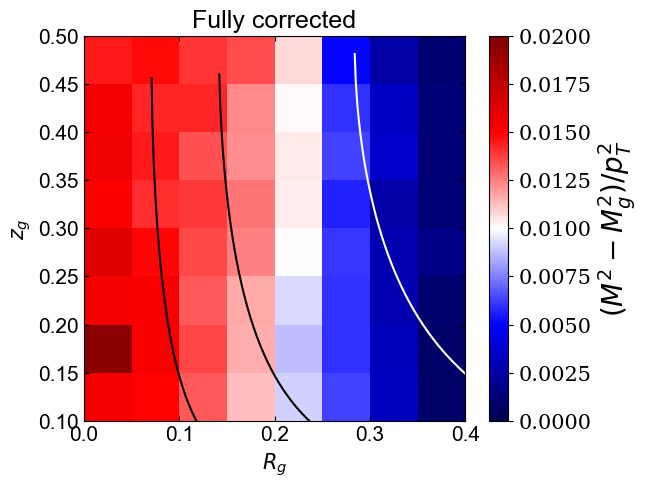

In [19]:
gs1 = gridspec.GridSpec(1,2,width_ratios=(1,12))

fig = plt.figure(figsize=(7,5))
plt.subplots_adjust(wspace=0.1, hspace=0)

ax1 = fig.add_subplot(gs1[1])
plt.pcolormesh(rgedges, zgedges, np.transpose(eff*z2+(1-eff)*z1), cmap='seismic')
#plt.errorbar(np.arange(0.025,0.425,0.05), y_1d, yerr=0, color='k')
#plt.text(0.05,0.2,'$p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ full jets, R=0.4, |$\eta$|<0.6\n\nMultiFolded with $p_\mathrm{T}, Q, M, M_g, R_g, z_g$\n\n$20 < p_\mathrm{T} < 30$ GeV/$c$', color='k',fontsize=10)
ax1.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both', labelcolor='k')
#ax1.axes.yaxis.set_ticklabels([])
#ax1.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
plt.ylabel(r'$z_g$')
plt.xlabel(r'$R_g$')
#plt.xticks(np.arange(0,1.1,0.1))
plt.clim(0,0.02)
plt.ylim(0.1,0.5)
plt.plot(x0,y0, color='white')
plt.plot(x1,y1, color='k')
plt.plot(x2,y2, color='k')
plt.title('Fully corrected')
cbar = plt.colorbar()
for l in cbar.ax.yaxis.get_ticklabels():
    l.set_family("serif")
cbar.set_label(r'$(M^2-M_g^2)/p_T^2$',font='arial',fontsize=20)

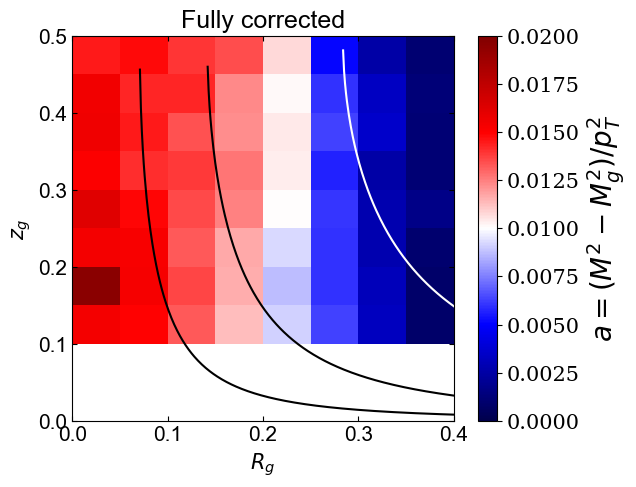

In [21]:
gs1 = gridspec.GridSpec(1,2,width_ratios=(1,12))

fig = plt.figure(figsize=(7,5))
plt.subplots_adjust(wspace=0.1, hspace=0)

ax1 = fig.add_subplot(gs1[1])
plt.pcolormesh(rgedges, zgedges, np.transpose(eff*z2+(1-eff)*z1), cmap='seismic')
#plt.errorbar(np.arange(0.025,0.425,0.05), y_1d, yerr=0, color='k')
#plt.text(0.05,0.2,'$p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ full jets, R=0.4, |$\eta$|<0.6\n\nMultiFolded with $p_\mathrm{T}, Q, M, M_g, R_g, z_g$\n\n$20 < p_\mathrm{T} < 30$ GeV/$c$', color='k',fontsize=10)
ax1.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both', labelcolor='k')
#ax1.axes.yaxis.set_ticklabels([])
#ax1.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
plt.ylabel(r'$z_g$')
plt.xlabel(r'$R_g$')
#plt.xticks(np.arange(0,1.1,0.1))
plt.clim(0,0.02)
plt.ylim(0.,0.5)
plt.plot(x0,y0, color='white')
plt.plot(x1,y1, color='k')
plt.plot(x2,y2, color='k')
plt.title('Fully corrected')
cbar = plt.colorbar()
for l in cbar.ax.yaxis.get_ticklabels():
    l.set_family("serif")
cbar.set_label(r'$a = (M^2-M_g^2)/p_T^2$',font='arial',fontsize=20)

In [20]:
path = '/gpfs/gibbs/project/caines/ys668/run12/csvs/'
ofCsvPath = 'herwig_newemb_7dreweight_6dunfold_largebatch_092723/'
ofCuts = '20<pt<30 and rg!=-1'
it = 15

df2s = []
for i in range(1,21):
    df_temp = pd.read_csv(path+ofCsvPath+'jet_noweight.csv', low_memory=False)
    df_temp.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
    df_temp.eval('loga=log10(a)',inplace=True)
    df_temp['weight'] = pd.read_csv(path+ofCsvPath+'it'+str(it)+'_seed'+str(i)+'.csv', low_memory=False)
    df2s.append(applyCut(df_temp, ofCuts))

In [21]:
w = []
for i in range(0, len(df2s)):
    w.append(np.asarray(df2s[i]['weight']))
w_avg=np.average(w,axis=0)
w_std=np.std(w,axis=0)
df2 = df2s[0]
df2['w_avg'] = w_avg
df2 = addNewBranches(df2)

In [22]:
z2_hw = np.zeros((len(rgedges)-1, len(zgedges)-1))
z2_hw_err = np.zeros((len(rgedges)-1, len(zgedges)-1))
for i in range(0, len(rgedges)-1):
    for j in range(0, len(zgedges)-1):
        df_temp = df2[(df2.rg>rgedges[i]) & (df2.rg<=rgedges[i+1]) & (df2.zg>zgedges[j]) & (df2.zg<=zgedges[j+1])]
        avg, err = weighted_avg_and_std(df_temp['a'], weights=df_temp['w_avg'])
        z2_hw[i][j] = avg
        z2_hw_err[i][j] = err

In [23]:
path = '/gpfs/gibbs/project/caines/ys668/run12/csvs/'
ofCsvPath = 'pythia8_newemb_7dreweight_6dunfold_largebatch_092723/'
ofCuts = '20<pt<30 and rg!=-1'
it = 15

df2s = []
for i in range(1,21):
    df_temp = pd.read_csv(path+ofCsvPath+'jet_noweight.csv', low_memory=False)
    df_temp.eval('a=(m*m-mg*mg)/(pt*pt)',inplace=True)
    df_temp.eval('loga=log10(a)',inplace=True)
    df_temp['weight'] = pd.read_csv(path+ofCsvPath+'it'+str(it)+'_seed'+str(i)+'.csv', low_memory=False)
    df2s.append(applyCut(df_temp, ofCuts))

In [24]:
w = []
for i in range(0, len(df2s)):
    w.append(np.asarray(df2s[i]['weight']))
w_avg=np.average(w,axis=0)
w_std=np.std(w,axis=0)
df2 = df2s[0]
df2['w_avg'] = w_avg
df2 = addNewBranches(df2)

In [25]:
z2_p8 = np.zeros((len(rgedges)-1, len(zgedges)-1))
z2_p8_err = np.zeros((len(rgedges)-1, len(zgedges)-1))
for i in range(0, len(rgedges)-1):
    for j in range(0, len(zgedges)-1):
        df_temp = df2[(df2.rg>rgedges[i]) & (df2.rg<=rgedges[i+1]) & (df2.zg>zgedges[j]) & (df2.zg<=zgedges[j+1])]
        avg, err = weighted_avg_and_std(df_temp['a'], weights=df_temp['w_avg'])
        z2_p8[i][j] = avg
        z2_p8_err[i][j] = err

In [26]:
err4 = z2_hw - z2
err5 = z2_p8 - z2
err_unf = np.zeros((len(rgedges)-1, len(zgedges)-1))
for i in range(0,len(rgedges)-1):
    for j in range(0,len(zgedges)-1):
        err_unf[i][j] = np.sqrt( (max(abs(err4[i][j]),abs(err5[i][j])))**2 ) 

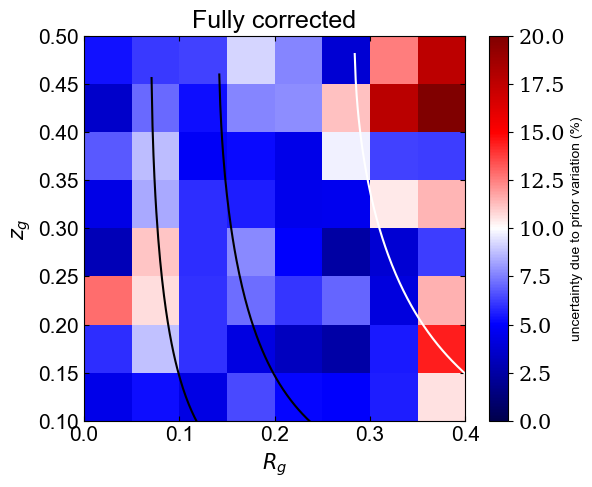

In [27]:
gs1 = gridspec.GridSpec(1,2,width_ratios=(1,12))

fig = plt.figure(figsize=(7,5))
plt.subplots_adjust(wspace=0.1, hspace=0)

ax1 = fig.add_subplot(gs1[1])
plt.pcolormesh(rgedges, zgedges, np.transpose(100*(eff*err_unf)/(eff*z2+(1-eff)*z1)), cmap='seismic')
#plt.errorbar(np.arange(0.025,0.425,0.05), y_1d, yerr=0, color='k')
#plt.text(0.05,0.2,'$p+p$  $\sqrt{s}=200$ GeV\nanti-$k_\mathrm{T}$ full jets, R=0.4, |$\eta$|<0.6\n\nMultiFolded with $p_\mathrm{T}, Q, M, M_g, R_g, z_g$\n\n$20 < p_\mathrm{T} < 30$ GeV/$c$', color='k',fontsize=10)
ax1.tick_params(top=True, right=True, bottom=True, left=True, direction='in', which='both', labelcolor='k')
#ax1.axes.yaxis.set_ticklabels([])
#ax1.axes.yaxis.set_minor_locator(MultipleLocator(0.05))
plt.ylabel(r'$z_g$')
plt.xlabel(r'$R_g$')
#plt.xticks(np.arange(0,1.1,0.1))
plt.clim(0,20)
plt.ylim(0.1,0.5)
plt.plot(x0,y0, color='white')
plt.plot(x1,y1, color='k')
plt.plot(x2,y2, color='k')
plt.title('Fully corrected')
cbar = plt.colorbar()
for l in cbar.ax.yaxis.get_ticklabels():
    l.set_family("serif")
cbar.set_label('uncertainty due to prior variation (%)',font='arial',fontsize=10)